# Informed Search

## Heuristics, Greedy Best-First Search and A*

### Learning Objectives

By the end of this lab, you will be able to:

- Understand what a heuristic function is.
- Use heuristic values to guide a search.
- Implement Greedy Best-First Search.
- Understand the idea behind the A* algorithm.
- Implement A* Search.
- Compare Greedy Best-First Search and A* Search.

## Informed Search

In **uninformed search**, the algorithm does not have any extra information about how close a node is to the goal.

In **informed search**, we use a **heuristic** to estimate how close a node is to the goal.

A heuristic is usually written as:

**h(n)** = estimated cost from node `n` to the goal.

For example, if we are trying to reach node `G`:

- `h(A) = 10` means A is estimated to be 10 units away from G.
- `h(B) = 6` means B is estimated to be 6 units away from G.
- `h(F) = 2` means F is estimated to be 2 units away from G.

A smaller heuristic value means that the node appears to be closer to the goal.

In [ ]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

## Problem Graph

We will use the following weighted graph.

Each edge has a **cost**, representing the actual cost of moving from one node to another.

Our goal is to find a path from:

**A → G**

We will use the same graph for both Greedy Best-First Search and A* Search.

In [ ]:
graph = {
    'A': [('B', 2), ('C', 5)],
    'B': [('A', 2), ('D', 4), ('E', 3)],
    'C': [('A', 5), ('F', 2)],
    'D': [('B', 4), ('G', 6)],
    'E': [('B', 3), ('F', 1)],
    'F': [('C', 2), ('E', 1), ('G', 3)],
    'G': [('D', 6), ('F', 3)]
}

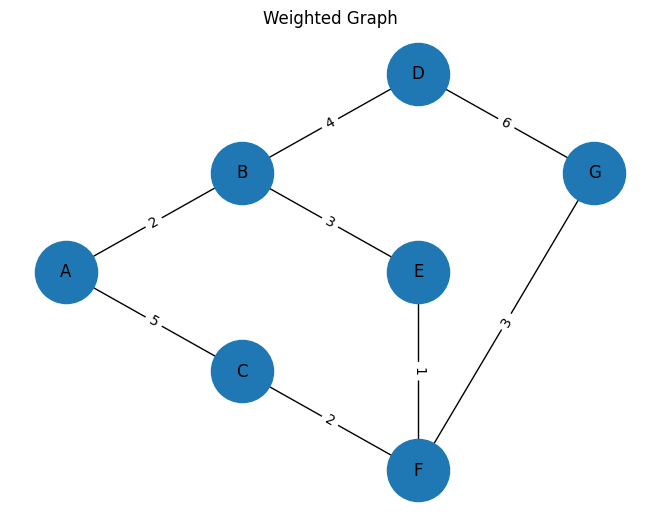

In [ ]:
G = nx.Graph()

for node in graph:
    for neighbor, cost in graph[node]:
        G.add_edge(node, neighbor, weight=cost)

pos = {
    'A': (0, 2),
    'B': (2, 3),
    'C': (2, 1),
    'D': (4, 4),
    'E': (4, 2),
    'F': (4, 0),
    'G': (6, 3)
}

edge_labels = nx.get_edge_attributes(G, 'weight')

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=2000,
    font_size=12
)

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title("Weighted Graph")
plt.show()

## Heuristic Function

Now we assign a heuristic value to each node.

The heuristic estimates the remaining cost from the current node to the goal `G`.

We will use:

**h(n) = estimated cost from n to G**

The goal has a heuristic of `0` because it is already at the goal.

A heuristic does not represent the actual cost already travelled. It only estimates the remaining cost.

In [ ]:
heuristic = {
    'A': 7,
    'B': 6,
    'C': 4,
    'D': 6,
    'E': 3,
    'F': 2,
    'G': 0
}

print("Heuristic values:")

for node, value in heuristic.items():
    print(f"h({node}) = {value}")

Heuristic values:
h(A) = 7
h(B) = 6
h(C) = 4
h(D) = 6
h(E) = 3
h(F) = 2
h(G) = 0


## Greedy Best-First Search

Greedy Best-First Search uses only the heuristic value to decide which node to explore next.

It uses:

**f(n) = h(n)**

The algorithm always chooses the node with the **smallest heuristic value**.

It does not consider how much cost has already been spent to reach the node.

Therefore, Greedy Best-First Search can find a path quickly, but the path is not always the cheapest possible path.

In [ ]:
def greedy_best_first_search(graph, heuristic, start, goal):

    priority_queue = []

    # Add the starting node
    heapq.heappush(
        priority_queue,
        (heuristic[start], start, [start])
    )

    visited = set()

    while priority_queue:

        h, current, path = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)

        # Check if goal is reached
        if current == goal:
            return path

        # Add neighboring nodes
        for neighbor, cost in graph[current]:

            if neighbor not in visited:

                heapq.heappush(
                    priority_queue,
                    (
                        heuristic[neighbor],
                        neighbor,
                        path + [neighbor]
                    )
                )

    return None

In [ ]:
start = 'A'
goal = 'G'

greedy_path = greedy_best_first_search(
    graph,
    heuristic,
    start,
    goal
)

print("Greedy Best-First Search Path:")
print(" → ".join(greedy_path))

Greedy Best-First Search Path:
A → C → F → G


## Calculating Path Cost

The path returned by a search algorithm is not enough.

We also need to calculate its **actual cost**.

The actual path cost is the sum of all edge costs along the path.

In [ ]:
def calculate_path_cost(graph, path):

    total_cost = 0

    for i in range(len(path) - 1):

        current = path[i]
        next_node = path[i + 1]

        for neighbor, cost in graph[current]:

            if neighbor == next_node:
                total_cost += cost
                break

    return total_cost

In [ ]:
greedy_cost = calculate_path_cost(
    graph,
    greedy_path
)

print("Greedy Path:", " → ".join(greedy_path))
print("Path Cost:", greedy_cost)

Greedy Path: A → C → F → G
Path Cost: 10


## A* Search

A* improves on Greedy Best-First Search by considering both:

- **g(n)** = actual cost from the start node to the current node
- **h(n)** = estimated cost from the current node to the goal

A* combines them using:

**f(n) = g(n) + h(n)**

The node with the smallest `f(n)` value is selected next.

This means A* considers both the cost already spent and the estimated cost remaining.

### Example

Suppose a node has:

- `g(n) = 5`
- `h(n) = 3`

Then:

**f(n) = g(n) + h(n)**

**f(n) = 5 + 3 = 8**

A* uses this value to decide which node should be explored next.

In [ ]:
def a_star_search(graph, heuristic, start, goal):

    priority_queue = []

    # (f, g, node, path)
    heapq.heappush(
        priority_queue,
        (0 + heuristic[start], 0, start, [start])
    )

    visited = set()

    while priority_queue:

        f, g, current, path = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)

        if current == goal:
            return path, g

        for neighbor, edge_cost in graph[current]:

            new_g = g + edge_cost
            h = heuristic[neighbor]
            new_f = new_g + h

            if neighbor not in visited:
                heapq.heappush(
                    priority_queue,
                    (new_f, new_g, neighbor, path + [neighbor])
                )

    return None, float('inf')

In [ ]:
astar_path, astar_cost = a_star_search(
    graph,
    heuristic,
    start,
    goal
)

print("A* Search Path:")
print(" → ".join(astar_path))

print("Path Cost:", astar_cost)

A* Search Path:
A → B → E → F → G
Path Cost: 9


In [ ]:
def greedy_with_trace(graph, heuristic, start, goal):

    priority_queue = []

    heapq.heappush(
        priority_queue,
        (heuristic[start], start, [start])
    )

    visited = set()

    expansion_order = []

    while priority_queue:

        h, current, path = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            return path, expansion_order

        for neighbor, cost in graph[current]:

            if neighbor not in visited:

                heapq.heappush(
                    priority_queue,
                    (
                        heuristic[neighbor],
                        neighbor,
                        path + [neighbor]
                    )
                )

    return None, expansion_order

In [ ]:
greedy_path, greedy_expansion = greedy_with_trace(
    graph,
    heuristic,
    start,
    goal
)

print("Greedy Path:")
print(" → ".join(greedy_path))

print("\nExpansion Order:")
print(" → ".join(greedy_expansion))

Greedy Path:
A → C → F → G

Expansion Order:
A → C → F → G
